# 1800-01 · PALMER1C: the matrix $A$ seen by CG

Companion to note `1800-01-GouldOrbanToint_2003_CUTEr_PALMER1C_Ill_Conditioned_Least_Squares.pdf`.

$f(a)=\|Va-y\|^2=2\varphi(a)+c$ with $\varphi(a)=\tfrac12a^\top Aa-b^\top a$, where
$V_{ik}=t_i^{\,k}$ ($t_i=x_i^2$, $k=0,\dots,7$), $A=V^\top V$, $b=V^\top y$.
CG is applied to $\varphi$ [HZ13, p. 2152]. What kind of matrix is $A$?

In [1]:
import re
from pathlib import Path
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

np.set_printoptions(formatter={"float_kind": lambda v: f"{v:.6e}"})

SIF_URL = "https://raw.githubusercontent.com/ralna/SIF/refs/heads/master/PALMER1C.SIF"

def read_sif(url):
    # (x, y) from the 'RE Xi' / 'RE Yi' lines; 
    with urllib.request.urlopen(url) as r:
        text = r.read().decode("utf-8")
    pat = lambda s: {int(i): float(v.replace("D", "E"))
                     for i, v in re.findall(rf"^\s*RE\s+{s}(\d+)\s+(\S+)", text, re.M)}
    x, y = pat("X"), pat("Y")
    return np.array([x[i] for i in sorted(x)]), np.array([y[i] for i in sorted(y)])

x, y = read_sif(SIF_URL)
t = x**2
V = np.vander(t, N=8, increasing=True)
A = V.T @ V
b = V.T @ y
print(f"V: {V.shape}   A: {A.shape}")

V: (35, 8)   A: (8, 8)


## 1. Structure

- $A$ is **dense** and **symmetric**.
<!--- $A$ is a **Hankel** matrix: $A_{jk}=s_{j+k}$ with $s_m=\sum_i t_i^{\,m}$ (moments of the nodes).
- Its entries range from $s_0=35$ to $s_{14}\approx1.8\times10^{8}$ (7 orders of magnitude).-->

In [2]:
print(f"symmetric : {np.array_equal(A, A.T)}")
print(f"entries   : min|A_jk| = {np.abs(A).min():.3e}, max|A_jk| = {np.abs(A).max():.3e}")

symmetric : True
entries   : min|A_jk| = 3.500e+01, max|A_jk| = 1.753e+08


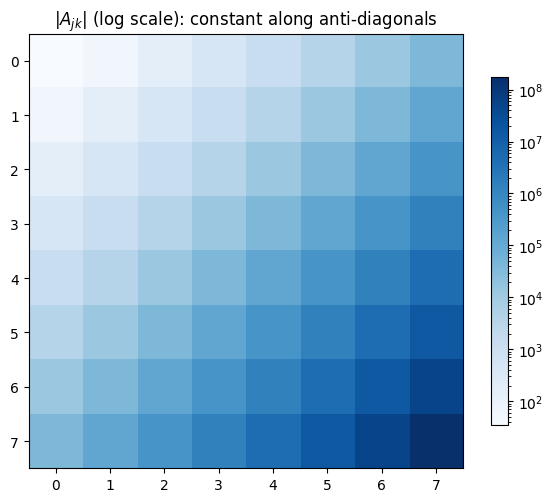

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(np.abs(A), cmap="Blues", norm=LogNorm(), interpolation="nearest")
ax.set_xticks(range(8)); ax.set_yticks(range(8))
ax.set_title(r"$|A_{jk}|$ (log scale): constant along anti-diagonals")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

## 2. Eigenvalues

In [4]:
eig = np.linalg.eigvalsh(A)
print(f"eig(A) = {eig}")
print("log10  = [" + ", ".join(f"{v:.2f}" for v in np.log10(eig)) + "]")

eig(A) = [1.521471e-04 1.027980e-02 2.664256e-01 4.303406e+00 1.978248e+01
 4.129271e+02 8.021893e+04 1.921789e+08]
log10  = [-3.82, -1.99, -0.57, 0.63, 1.30, 2.62, 4.90, 8.28]


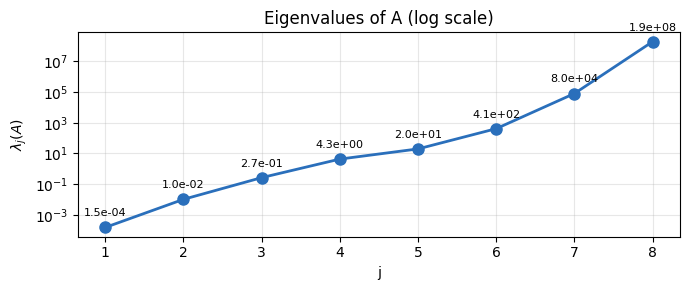

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(range(1, 9), eig, "o-", color="#2a6fbb", lw=2, ms=8)
for j, lam in enumerate(eig, 1):
    ax.annotate(f"{lam:.1e}", (j, lam), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8)
ax.set_xlabel("j"); ax.set_ylabel(r"$\lambda_j(A)$")
ax.set_title("Eigenvalues of A (log scale)")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Eigenvalues go from $1.5\times10^{-4}$ to $1.9\times10^{8}$ (12 orders of magnitude), as in
[HZ13, p. 2150]. They are spread out on a log scale, with no clusters.

## 3. Properties that matter for CG

In [6]:
np.linalg.cholesky(A)                        # fails if A is not SPD
kappa = eig[-1] / eig[0]
rate = (np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)
u = np.finfo(float).eps / 2

print(f"positive definite        : {np.all(eig > 0)} (Cholesky ok)")
print(f"distinct eigenvalues     : {np.unique(eig).size}")
print(f"kappa(A)                 : {kappa:.3e}")
print(f"CG rate (sqrt(k)-1)/(sqrt(k)+1) : {rate:.10f}")
print(f"u * kappa(A)             : {u * kappa:.1e}")

positive definite        : True (Cholesky ok)
distinct eigenvalues     : 8
kappa(A)                 : 1.263e+12
CG rate (sqrt(k)-1)/(sqrt(k)+1) : 0.9999982205
u * kappa(A)             : 1.4e-04


| Property | Value | Meaning for CG |
|---|---|---|
| Symmetric positive definite | yes | CG applies; $\varphi$ has a unique minimizer $a^*=A^{-1}b$ |
| Size | $8\times8$, dense | — |
| Distinct eigenvalues | 8 | exact arithmetic: CG terminates in $\le 8$ iterations |
| $\kappa(A)$ | $\approx1.26\times10^{12}$ | bound $\|e_k\|_A\le2\,r^k\|e_0\|_A$ with $r\approx1-1.8\times10^{-6}$: useless |
| $u\,\kappa(A)$ | $\approx1.4\times10^{-4}$ | rounding errors are strongly amplified: orthogonality of the gradients is lost |

### References

- [HZ13] W. W. Hager and H. Zhang, The limited memory conjugate gradient method, *SIAM J. Optim.*, 23 (2013), pp. 2150–2168.